In [1]:
!pip install pandas scikit-learn matplotlib joblib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 1: Importing Required Libraries

In [2]:
import warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, VotingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_PATH = "Sleep_health_and_lifestyle_dataset.csv"

## Step 2: Loading and Inspecting the Dataset
- The label "None" (no sleep disorder) is a real category, but pandas treats the text "None" as a missing value by default.
`keep_default_na=False` stops that from happening. 

In [3]:
df_raw = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""])

print("Shape:", df_raw.shape)
display(df_raw.head())
print("\nMissing values per column:")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0] if df_raw.isna().any().any() else "None")

Shape: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea



Missing values per column:
None


In [4]:
# Duplicates check: ignoring Person ID (since it is unique per row, so it hides the duplicates)
feature_cols_raw = [c for c in df_raw.columns if c != "Person ID"]
n_dup = df_raw.duplicated(subset=feature_cols_raw).sum()
n_unique = len(df_raw) - n_dup

print(f"Total rows:            {len(df_raw)}")
print(f"Duplicate rows:        {n_dup}")
print(f"Unique rows:           {n_unique}")
print("\nClass counts (all rows):")
print(df_raw["Sleep Disorder"].value_counts())
print("\nClass counts (unique rows only):")
print(df_raw.drop_duplicates(subset=feature_cols_raw)["Sleep Disorder"].value_counts())

Total rows:            374
Duplicate rows:        242
Unique rows:           132

Class counts (all rows):
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

Class counts (unique rows only):
Sleep Disorder
None           73
Sleep Apnea    30
Insomnia       29
Name: count, dtype: int64


## Step 3: Data Cleaning
- dropping `Person ID` (no predictive meaning)
- merging the two spellings of "Normal" weight
- splitting `Blood Pressure` ("126/83") into systolic and diastolic numbers
- renaming columns to simple names in lowercase (the app uses the same names later)
- **removing duplicate rows before any splitting**

In [5]:
df = df_raw.drop(columns=["Person ID"]).copy()

# stripping stray spaces in text columns
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()

df["BMI Category"] = df["BMI Category"].replace({"Normal Weight": "Normal"})

bp = df["Blood Pressure"].str.split("/", expand=True).astype(int)
df["systolic"], df["diastolic"] = bp[0], bp[1]
df = df.drop(columns=["Blood Pressure"])

df = df.rename(columns={
    "Gender": "gender", "Age": "age", "Occupation": "occupation",
    "Sleep Duration": "sleep_duration", "Quality of Sleep": "sleep_quality",
    "Physical Activity Level": "physical_activity", "Stress Level": "stress_level",
    "BMI Category": "bmi_category", "Heart Rate": "heart_rate",
    "Daily Steps": "daily_steps", "Sleep Disorder": "sleep_disorder",
})

TARGET = "sleep_disorder"
CAT_COLS = ["gender", "occupation", "bmi_category"]
NUM_COLS = ["age", "sleep_duration", "sleep_quality", "physical_activity", "stress_level",
            "systolic", "diastolic", "heart_rate", "daily_steps"]
FEATURES = CAT_COLS + NUM_COLS

df_full = df.copy()                              # with duplicates (kept only for the leakage demo)
df_clean = df.drop_duplicates().reset_index(drop=True)   # the honest dataset
print(f"With duplicates: {len(df_full)} rows  ->  after de-duplication: {len(df_clean)} rows")
display(df_clean.head())

With duplicates: 374 rows  ->  after de-duplication: 132 rows


,gender,age,occupation,sleep_duration,sleep_quality,physical_activity,stress_level,bmi_category,heart_rate,daily_steps,sleep_disorder,systolic,diastolic
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126,83
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
2,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
3,Male,28,Software Engineer,5.9,4,30,8,Obese,85,3000,Insomnia,140,90
4,Male,29,Teacher,6.3,6,40,7,Obese,82,3500,Insomnia,140,90


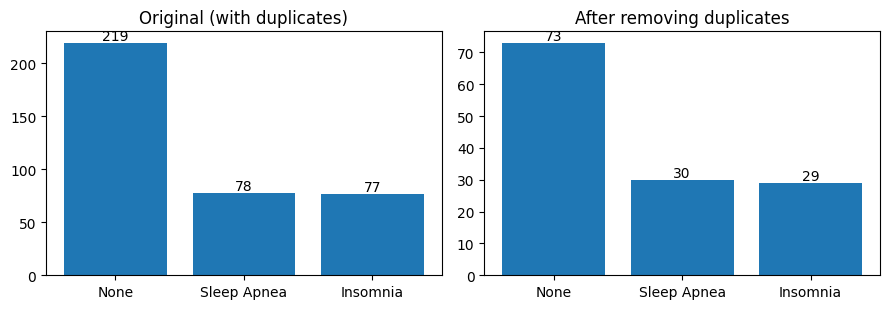

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=False)
order = ["None", "Sleep Apnea", "Insomnia"]
for ax, data, title in zip(axes, [df_full, df_clean], ["Original (with duplicates)", "After removing duplicates"]):
    counts = data[TARGET].value_counts().reindex(order)
    ax.bar(counts.index, counts.values)
    ax.set_title(title)
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

## Step 4: Splitting dataset and training model

In [8]:
# Leakage demo: random split on the ORIGINAL data (with duplicates)
X_all, y_all = df_full[FEATURES], df_full[TARGET]
Xtr_n, Xte_n, ytr_n, yte_n = train_test_split(X_all, y_all, test_size=0.25, random_state=RANDOM_STATE, stratify=y_all)

# how many test rows have an identical twin in the training set?
twin = Xte_n.merge(Xtr_n.drop_duplicates(), on=FEATURES, how="left", indicator=True)
leak_pct = (twin["_merge"] == "both").mean() * 100
print(f"Test rows that also appear in the training set (duplicate-split): {leak_pct:.1f}%")

def make_pre(scale):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        ("num", StandardScaler() if scale else "passthrough", NUM_COLS),
    ])

naive_rf = Pipeline([("pre", make_pre(False)), ("clf", RandomForestClassifier(random_state=RANDOM_STATE))])
naive_rf.fit(Xtr_n, ytr_n)
naive_acc = accuracy_score(yte_n, naive_rf.predict(Xte_n))
print(f"Random Forest accuracy with duplicates in both sets:  {naive_acc*100:.1f}%  (inflated)")

Test rows that also appear in the training set (duplicate-split): 88.3%
Random Forest accuracy with duplicates in both sets:  94.7%  (inflated)


In [9]:
X, y = df_clean[FEATURES], df_clean[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nTest class counts:\n", y_test.value_counts())

def build_models():
    return {
        "Baseline (majority class)": Pipeline([("pre", make_pre(False)), ("clf", DummyClassifier(strategy="most_frequent"))]),
        "KNN":  Pipeline([("pre", make_pre(True)),  ("clf", KNeighborsClassifier())]),
        "SVM":  Pipeline([("pre", make_pre(True)),  ("clf", SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE))]),
        "Decision Tree": Pipeline([("pre", make_pre(False)), ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
        "Random Forest": Pipeline([("pre", make_pre(False)), ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE))]),
        "ANN (MLP)": Pipeline([("pre", make_pre(True)), ("clf", MLPClassifier(max_iter=2000, random_state=RANDOM_STATE))]),
        "Voting (DT + Bagging RF)": Pipeline([("pre", make_pre(False)), ("clf", VotingClassifier(
            estimators=[
                ("dt", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
                ("bag_rf", BaggingClassifier(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                                             n_estimators=10, random_state=RANDOM_STATE)),
            ], voting="soft"))]),
    }

models = build_models()
for name, m in models.items():
    m.fit(X_train, y_train)
print("\nAll models trained.")

Train: (99, 12)  Test: (33, 12)

Test class counts:
 sleep_disorder
None           18
Sleep Apnea     8
Insomnia        7
Name: count, dtype: int64

All models trained.


## Step 4: Honest Evaluation
With only ~100 unique rows, a single 25% test set is tiny and noisy, so one lucky split can mislead.
We therefore report **repeated stratified 5-fold cross-validation** (15 train/test rounds) as the main result, and the single hold-out split as a secondary view.
Macro-averaged precision/recall/F1 treat all three classes equally, which matters because "None" is the biggest class.

In [10]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}

cv_rows = []
for name, m in build_models().items():
    res = cross_validate(m, X, y, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({
        "Model": name,
        "CV Accuracy": res["test_accuracy"].mean(), "CV Acc (std)": res["test_accuracy"].std(),
        "CV Precision": res["test_precision"].mean(),
        "CV Recall": res["test_recall"].mean(),
        "CV F1 (macro)": res["test_f1"].mean(),
    })
cv_table = pd.DataFrame(cv_rows).set_index("Model")

hold_rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    hold_rows.append({"Model": name, "Hold-out Accuracy": accuracy_score(y_test, pred),
                      "Hold-out Precision": p, "Hold-out Recall": r, "Hold-out F1 (macro)": f})
hold_table = pd.DataFrame(hold_rows).set_index("Model")

results = cv_table.join(hold_table).round(3)
display(results.sort_values("CV F1 (macro)", ascending=False))

  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


,CV Accuracy,CV Acc (std),CV Precision,CV Recall,CV F1 (macro),Hold-out Accuracy,Hold-out Precision,Hold-out Recall,Hold-out F1 (macro)
Model,,,,,,,,,
SVM,0.707,0.097,0.666,0.661,0.648,0.667,0.662,0.622,0.615
KNN,0.692,0.068,0.646,0.631,0.617,0.667,0.662,0.622,0.615
ANN (MLP),0.669,0.088,0.616,0.627,0.607,0.667,0.631,0.622,0.614
Random Forest,0.591,0.077,0.510,0.526,0.508,0.636,0.616,0.552,0.549
Voting (DT + Bagging RF),0.563,0.085,0.487,0.496,0.484,0.636,0.616,0.552,0.549
Decision Tree,0.515,0.062,0.453,0.460,0.446,0.636,0.616,0.552,0.549
Baseline (majority class),0.553,0.014,0.184,0.333,0.237,0.545,0.182,0.333,0.235


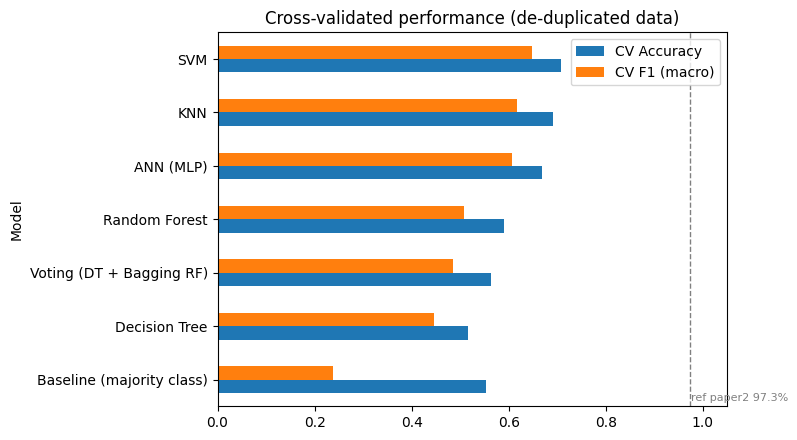

In [12]:
# Bar chart of the main (cross-validated) result
plot_df = cv_table[["CV Accuracy", "CV F1 (macro)"]].sort_values("CV F1 (macro)")
ax = plot_df.plot(kind="barh", figsize=(8, 4.5))
ax.set_xlim(0, 1.05); ax.set_title("Cross-validated performance (de-duplicated data)")
ax.axvline(0.973, ls="--", lw=1, color="grey"); ax.text(0.975, -0.4, "ref paper2 97.3%", fontsize=8, color="grey")
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=150); plt.show()

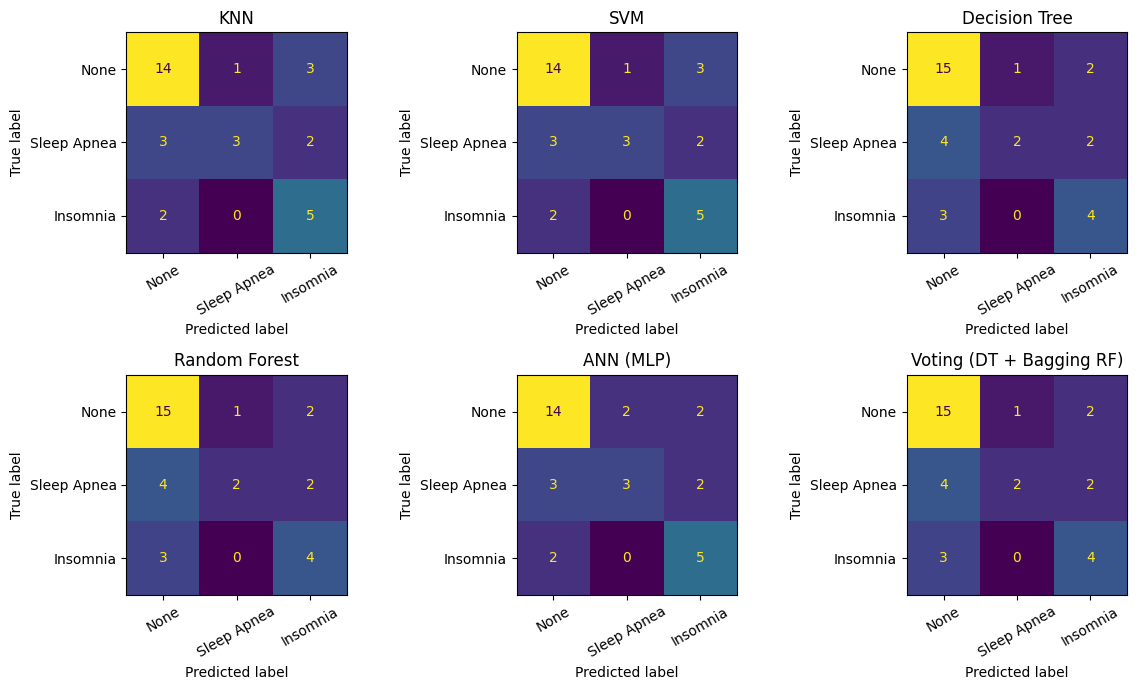

In [13]:
# Confusion matrices on the hold-out set for the real models
labels = ["None", "Sleep Apnea", "Insomnia"]
real_models = [n for n in models if not n.startswith("Baseline")]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, name in zip(axes.ravel(), real_models):
    cm = confusion_matrix(y_test, models[name].predict(X_test), labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, xticks_rotation=30)
    ax.set_title(name)
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150); plt.show()

## Step 5: Choosing and saving the model, plus a simple explanation
The deployed model is the **best model overall by cross-validated macro-F1** (on this data that is the SVM).
It is then re-trained on **all** the de-duplicated data, which is standard practice once evaluation is finished.

Because an SVM has no built-in feature importances, we explain it in two model-agnostic ways that need no extra library:
1. **Global:** permutation importance (shuffle one feature and see how much the score drops).
2. **Per person:** replace one feature at a time with values seen in the data and see how the predicted probability moves. This is the "why did this person get this result" view the app will show. (SHAP can replace it later as an optional upgrade.)

In [14]:
real_candidates = [n for n in cv_table.index if not n.startswith("Baseline")]
deployed_name = cv_table.loc[real_candidates, "CV F1 (macro)"].idxmax()
print("Deployed model:", deployed_name)

deployed = build_models()[deployed_name]
deployed.fit(X, y)          # final fit on all de-duplicated data
print("Classes:", list(deployed.named_steps["clf"].classes_))

Deployed model: SVM
Classes: ['Insomnia', 'None', 'Sleep Apnea']


,drop in F1 when shuffled
heart_rate,0.028
systolic,0.015
diastolic,0.012
occupation,0.006
age,0.005
gender,0.000
sleep_quality,-0.001
bmi_category,-0.004
stress_level,-0.004
sleep_duration,-0.005


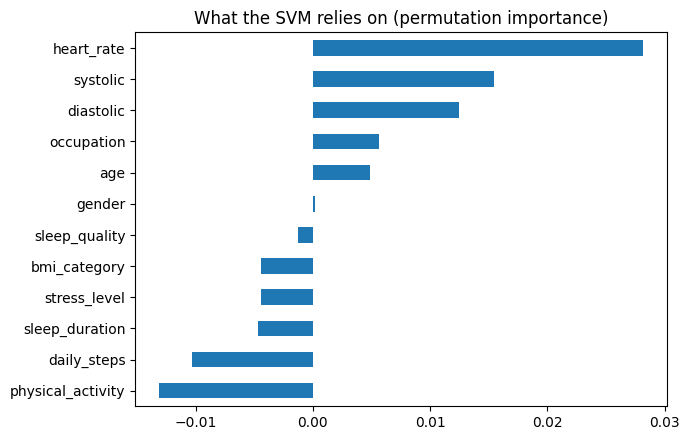

In [15]:
# Global explanation: permutation importance on the deployed model (works for ANY model type)
from sklearn.inspection import permutation_importance
perm = permutation_importance(deployed, X, y, n_repeats=30, random_state=RANDOM_STATE, scoring="f1_macro")
global_importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
display(global_importance.round(3).to_frame("drop in F1 when shuffled"))

ax = global_importance.sort_values().plot(kind="barh", figsize=(7, 4.5))
ax.set_title(f"What the {deployed_name} relies on (permutation importance)")
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=150); plt.show()

In [16]:
# Per-person explanation: how much does each input push the model toward its predicted answer?
def explain_person(pipe, row, background, n_values=40, seed=RANDOM_STATE):
    """Returns (predicted_class, probabilities, effects).
    effect > 0  : this input pushed the prediction TOWARD the predicted class
    effect < 0  : this input pushed it AWAY from the predicted class
    Method: swap one input at a time with typical values from the data and see how the probability changes."""
    classes = list(pipe.named_steps["clf"].classes_)
    base = pipe.predict_proba(row)[0]
    k = int(np.argmax(base))
    effects = {}
    for col in FEATURES:
        vals = background[col].sample(min(n_values, len(background)), random_state=seed).to_numpy()
        trial = pd.concat([row] * len(vals), ignore_index=True)
        trial[col] = vals
        effects[col] = base[k] - pipe.predict_proba(trial)[:, k].mean()
    return classes[k], dict(zip(classes, base)), pd.Series(effects).sort_values(key=abs, ascending=False)

sample_for_explain = pd.DataFrame([{
    "gender": "Male", "age": 40, "occupation": df_clean["occupation"].mode()[0],
    "sleep_duration": 6.0, "sleep_quality": 5, "physical_activity": 40, "stress_level": 8,
    "bmi_category": "Overweight", "systolic": 135, "diastolic": 88, "heart_rate": 80, "daily_steps": 4000,
}])[FEATURES]
pred, probs, effects = explain_person(deployed, sample_for_explain, X)
print("Predicted:", pred, {k: round(float(v), 2) for k, v in probs.items()})
print("\nTop reasons (positive = pushed toward this result):")
print(effects.head(5).round(3))

Predicted: Insomnia {'Insomnia': 0.54, 'None': 0.12, 'Sleep Apnea': 0.34}

Top reasons (positive = pushed toward this result):
daily_steps          0.092
systolic             0.074
sleep_quality        0.055
diastolic            0.053
physical_activity    0.053
dtype: float64


In [17]:
# Quick sanity test: predict one made-up person
sample = pd.DataFrame([{
    "gender": "Male", "age": 40, "occupation": df_clean["occupation"].mode()[0],
    "sleep_duration": 6.0, "sleep_quality": 5, "physical_activity": 40, "stress_level": 8,
    "bmi_category": "Overweight", "systolic": 135, "diastolic": 88, "heart_rate": 80, "daily_steps": 4000,
}])[FEATURES]
proba = deployed.predict_proba(sample)[0]
print("Prediction:", deployed.predict(sample)[0])
print(dict(zip(deployed.named_steps["clf"].classes_, proba.round(3))))

Prediction: Insomnia
{'Insomnia': np.float64(0.539), 'None': np.float64(0.117), 'Sleep Apnea': np.float64(0.344)}


In [18]:
# Saving everything the Streamlit app will need
joblib.dump(deployed, "sleep_model.joblib")
df_clean.to_csv("clean_data.csv", index=False)
results.to_csv("model_comparison.csv")
global_importance.to_csv("global_importance.csv", header=["importance"])

metadata = {
    "deployed_model": deployed_name,
    "classes": list(deployed.named_steps["clf"].classes_),
    "features": FEATURES, "cat_cols": CAT_COLS, "num_cols": NUM_COLS,
    "categories": {c: sorted(df_clean[c].unique().tolist()) for c in CAT_COLS},
    "numeric_ranges": {c: {"min": float(df_clean[c].min()), "max": float(df_clean[c].max()),
                           "median": float(df_clean[c].median())} for c in NUM_COLS},
    "data_summary": {"rows_original": int(len(df_full)), "rows_after_dedup": int(len(df_clean)),
                     "duplicate_test_leak_pct_naive_split": round(float(leak_pct), 1),
                     "naive_rf_accuracy": round(float(naive_acc), 3)},
    "cv_results": results["CV Accuracy"].to_dict(),
}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved: sleep_model.joblib, clean_data.csv, model_comparison.csv, global_importance.csv, model_metadata.json")
print("Plots: class_distribution.png, model_comparison.png, confusion_matrices.png, feature_importance.png")

Saved: sleep_model.joblib, clean_data.csv, model_comparison.csv, global_importance.csv, model_metadata.json
Plots: class_distribution.png, model_comparison.png, confusion_matrices.png, feature_importance.png
